# 01b · Exploración del dataset Montgomery-Shenzhen

Este dataset es el **conjunto de entrenamiento de los segmentadores**: 704 radiografías
de tórax con máscaras pulmonares trazadas manualmente. Lo necesito porque TBX11K
(notebook 01a) no tiene máscaras de pulmón.

Combino las dos fuentes desde el inicio como un único conjunto:
- **Montgomery County** (EE. UU.), NLM / Jaeger et al., 2014: 138 imágenes, máscara bilateral.
- **Shenzhen** (China), NLM / Candemir et al., 2014: 566 imágenes con máscara en esta versión de Kaggle.

El objetivo final del proyecto es detectar TB con características radiómicas extraídas
dentro de distintas segmentaciones pulmonares. Por eso me interesa especialmente:
- la calidad y la consistencia de las máscaras manuales (son la referencia gold-standard), y
- los sesgos o confusores que puedan afectar la comparación entre métodos.

**Relación con el resto del proyecto**

```
01a (TBX11K) ──┐
               ├──► 02 (segmentación) ──► 03 (radiómics) ──► ...
01b (este)  ───┘
```
Las máscaras de este dataset se usan para entrenar U-Net, Attention U-Net y (próximamente)
MedSAM. Una vez entrenados, los modelos generan máscaras para TBX11K.

**El notebook escribe** `data/metadata/montgomery_shenzhen_index.csv`
al final de la sección 7.

## 1 · Configuración del entorno

In [1]:
import hashlib
import re
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Importo desde el módulo del proyecto para usar exactamente la misma lógica
# que usa el entrenamiento: rutas, identificador de fuente y resolución de máscaras.
from tbseg.config import MS_INDEX_CSV, SEED, SEGTRAIN_RAW_DIR
from tbseg.segmentation.prepare import SOURCES, mask_path, patient_ids

IMG_DIR  = SEGTRAIN_RAW_DIR / "CXR_png"
READ_DIR = SEGTRAIN_RAW_DIR / "ClinicalReadings"

rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 110)

# ── Paletas de colores ─────────────────────────────────────────────────────────
CLASS_NAMES   = {0: "normal", 1: "TB"}
CLASS_COLORS  = {0: "#2a78d6", 1: "#eb6834"}
SOURCE_ORDER  = ["montgomery", "shenzhen"]
SOURCE_COLORS = {"montgomery": "#1baf7a", "shenzhen": "#4a3aa7"}

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "figure.dpi": 100,
})

## 2 · Estructura del dataset

El directorio `data/external/montgomery_shenzhen/` tiene esta organización:

```
montgomery_shenzhen/
├── CXR_png/           radiografías  →  <prefijo>_<número>_<0|1>.png
│                                        0 = normal, 1 = TB
├── masks/             máscaras pulmonares (un solo archivo por imagen)
│                       Shenzhen: <id>_mask.png
│                       Montgomery: <id>.png  (sin sufijo _mask)
├── ClinicalReadings/  un .txt por imagen con sexo, edad y hallazgo radiológico
└── NLM-*-ReadMe.*     documentación original de cada fuente
```

El prefijo identifica la fuente: `MCUCXR` = Montgomery County, `CHNCXR` = Shenzhen.

### 2.1 Correspondencia imagen-máscara-lectura clínica

In [2]:
# Construyo un índice inicial con una fila por imagen.
# Verifico que cada imagen tenga su máscara y su lectura clínica.
index = pd.DataFrame(
    {
        "image_id":    p.stem,
        # SOURCES mapea el prefijo del nombre al nombre de la fuente
        "source":      SOURCES[p.stem.split("_")[0]],
        # La clase está codificada en el sufijo del nombre de archivo
        "tb":          int(p.stem.endswith("_1")),
        "has_mask":    mask_path(p.stem).exists(),
        "has_reading": (READ_DIR / f"{p.stem}.txt").exists(),
    }
    for p in sorted(IMG_DIR.glob("*.png"))
)

# Compruebo también la dirección contraria: máscaras o lecturas sin imagen
mask_ids = {p.stem.removesuffix("_mask") for p in (SEGTRAIN_RAW_DIR / "masks").glob("*.png")}
read_ids  = {p.stem for p in READ_DIR.glob("*.txt")}

print(f"Imágenes: {len(index)}")
print(f"  con máscara:  {index['has_mask'].sum()}")
print(f"  con lectura:  {index['has_reading'].sum()}")
print(f"Máscaras sin imagen:  {len(mask_ids - set(index['image_id']))}")
print(f"Lecturas sin imagen:  {len(read_ids  - set(index['image_id']))}")
print()

counts = pd.crosstab(index["source"], index["tb"].map(CLASS_NAMES),
                     margins=True, margins_name="total")
counts["% TB"] = (100 * counts["TB"] / counts["total"]).round(1)
display(counts)

Imágenes: 800
  con máscara:  704
  con lectura:  800
Máscaras sin imagen:  0
Lecturas sin imagen:  0



tb,TB,normal,total,% TB
source,,,,
montgomery,58,80,138,42.0
shenzhen,336,326,662,50.8
total,394,406,800,49.2


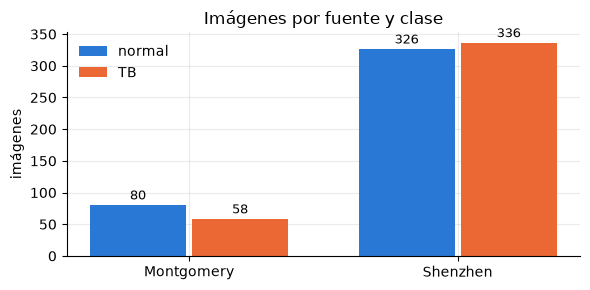

In [3]:
# Gráfico de barras: imágenes por fuente y clase
fig, ax = plt.subplots(figsize=(6, 3))
width = 0.38
x = np.arange(len(SOURCE_ORDER))
for k, (tb, name) in enumerate(CLASS_NAMES.items()):
    vals = [((index["source"] == s) & (index["tb"] == tb)).sum() for s in SOURCE_ORDER]
    bars = ax.bar(x + (k - 0.5) * width, vals, width * 0.94,
                  color=CLASS_COLORS[tb], label=name)
    ax.bar_label(bars, padding=2, fontsize=9)
ax.set_xticks(x, [s.capitalize() for s in SOURCE_ORDER])
ax.set_ylabel("imágenes")
ax.set_title("Imágenes por fuente y clase")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Todas las 704 imágenes tienen su máscara y su lectura clínica; no hay archivos huérfanos.

La versión original de Shenzhen tiene 662 imágenes; la versión de Kaggle conserva
solo las **566 con máscara**. Montgomery está completo (138).

Shenzhen aporta el 80 % del dataset. Las clases quedan casi balanceadas en el
conjunto global, pero la proporción de TB difiere entre fuentes.

## 3 · Metadatos clínicos

Cada fuente usa un formato de lectura diferente:
- **Montgomery**: `Patient's Sex: F` / `Patient's Age: 027Y` / hallazgo en texto libre.
- **Shenzhen**: `male 45yrs` (con variantes: `femal`, `male, 35yrs`, `male 35yr`, `1month`)
  seguido del hallazgo.

Escribo un parser que normaliza ambos formatos a tres campos: `sex`, `age` (en años)
y `finding`.

In [4]:
# Tabla de conversión: texto del archivo → código normalizado
SEX_CODES = {"m": "M", "male": "M", "f": "F", "female": "F", "femal": "F", "o": "O"}
# Factor de conversión al año: año=1, mes=1/12, día=1/365
AGE_UNITS  = {"y": 1, "m": 1 / 12, "d": 1 / 365}


def parse_reading(text: str, source: str) -> dict:
    """Extrae sexo, edad (en años) y hallazgo radiológico de una lectura clínica.

    El formato difiere entre Montgomery y Shenzhen, por eso uso una rama por fuente.
    """
    lines = [line.strip() for line in text.splitlines() if line.strip()]

    if source == "montgomery":
        sex     = re.search(r"Sex:\s*(\w)", text)
        age     = re.search(r"Age:\s*(\d+)\s*([YMD])", text, re.I)
        finding = lines[2:]          # las primeras dos líneas son sexo y edad
    else:
        sex     = re.match(r"(female|femal|male)", lines[0], re.I)
        age     = re.search(r"(\d+)\s*(y|m|d)?", lines[0], re.I)
        finding = lines[1:]          # la primera línea contiene sexo y edad

    unit = (age.group(2) or "y").lower() if age else "y"
    return {
        "sex":     SEX_CODES.get(sex.group(1).lower()) if sex else None,
        "age":     round(int(age.group(1)) * AGE_UNITS[unit], 2) if age else np.nan,
        "finding": " | ".join(finding),
    }


# Aplico el parser y uno el resultado al índice
meta  = pd.DataFrame(
    [
        parse_reading((READ_DIR / f"{i}.txt").read_text(errors="replace"), s)
        for i, s in zip(index["image_id"], index["source"])
    ]
)
index = pd.concat([index.drop(columns=["has_mask", "has_reading"]), meta], axis=1)

print("Lecturas sin sexo:", index["sex"].isna().sum(),
      "| sin edad:", index["age"].isna().sum())
print("Códigos de sexo:", index["sex"].value_counts().to_dict())
index.groupby("source").sample(3, random_state=SEED)[
    ["image_id", "tb", "sex", "age", "finding"]
]

Lecturas sin sexo: 0 | sin edad: 0
Códigos de sexo: {'M': 512, 'F': 287, 'O': 1}


,image_id,tb,sex,age,finding
751,MCUCXR_0150_1,1,M,32.0,extensive infiltrates bilaterally with large cavity in RUL and a moderate pleural effusion on the left. AF...
767,MCUCXR_0251_1,1,F,77.0,RUL fibrocavitary disease with volume loss and tracheal deviation to right; COPD scoliosis;
674,MCUCXR_0019_0,0,M,33.0,normal
598,CHNCXR_0599_1,1,M,39.0,Right PTB
590,CHNCXR_0591_1,1,M,46.0,right lower field PTB
209,CHNCXR_0210_0,0,M,27.0,normal


### 3.1 Pacientes repetidos (control de fuga de información)

In [5]:
# Algunas lecturas de Montgomery dicen "same pt as MCUCXR_…": el mismo paciente
# tiene varias radiografías tomadas en momentos distintos. Si esas imágenes
# caen en particiones distintas, el modelo evalúa sobre un paciente que ya vio,
# lo que infla artificialmente las métricas.
#
# Uso patient_ids() de prepare.py —la misma función que define la partición de
# entrenamiento— para asignar un identificador común a todas las imágenes del
# mismo paciente.

index["patient_id"] = index["image_id"].map(patient_ids(index["image_id"]))

repeated = index[index.duplicated("patient_id", keep=False)].sort_values("patient_id")
print(f"Imágenes de pacientes repetidos: {len(repeated)} en {repeated['patient_id'].nunique()} pacientes")
repeated[["image_id", "patient_id", "tb", "sex", "age", "finding"]]

Imágenes de pacientes repetidos: 5 en 2 pacientes


,image_id,patient_id,tb,sex,age,finding
744,MCUCXR_0113_1,MCUCXR_0113_1,1,F,84.0,bilateral miliary nodules diffusely with RML infiltrate and right pleural effusion; an old calcified granu...
745,MCUCXR_0117_1,MCUCXR_0113_1,1,F,85.0,stable CXR since 6M; off Rx since 6M (same pt as MCUCXR_0113_1)
752,MCUCXR_0162_1,MCUCXR_0162_1,1,M,49.0,RUL apical fibrotic disease with some calcifications; extensive irregular infiltrates in left lung with a ...
753,MCUCXR_0166_1,MCUCXR_0162_1,1,M,49.0,NO REPORT (same pt as MCUCXR_0162_1)
754,MCUCXR_0170_1,MCUCXR_0162_1,1,M,49.0,"CXR similar to prior views 1M and 2M ago with some slight improvement; on HRZ(E)x2 months, AFB smears neg ..."


### 3.2 Distribución de sexo y edad por clase

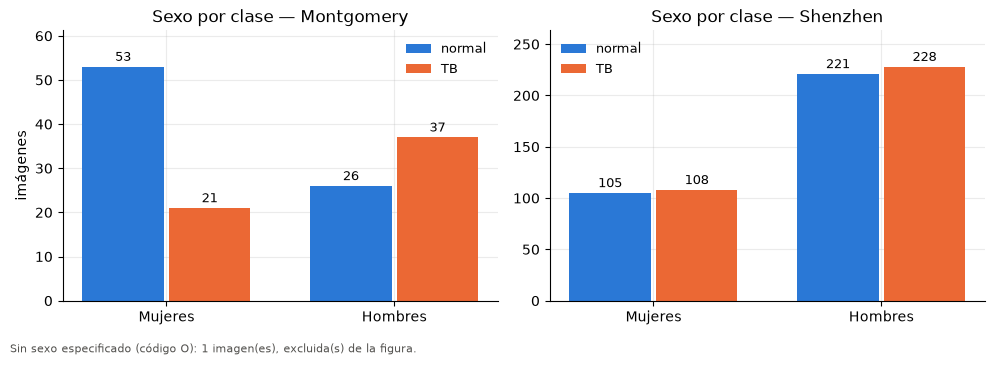

In [6]:
# Sexo y edad no entran en los modelos de clasificación de TB.
# Los resumo aquí para la tabla descriptiva del informe y para verificar
# que no haya sesgos demográficos que confundan la comparación entre métodos.

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
SEX_LABELS = {"F": "Mujeres", "M": "Hombres"}
width = 0.38
x = np.arange(len(SEX_LABELS))

for ax, source in zip(axes, SOURCE_ORDER):
    sub = index[index["source"] == source]
    for k, (tb, name) in enumerate(CLASS_NAMES.items()):
        vals = [((sub["sex"] == sex) & (sub["tb"] == tb)).sum() for sex in SEX_LABELS]
        bars = ax.bar(x + (k - 0.5) * width, vals, width * 0.94,
                      color=CLASS_COLORS[tb], label=name)
        ax.bar_label(bars, padding=2, fontsize=9)
    ax.set_xticks(x, list(SEX_LABELS.values()))
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.set_title(f"Sexo por clase — {source.capitalize()}")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("imágenes")

n_other = (~index["sex"].isin(SEX_LABELS)).sum()
fig.text(0.01, 0.005,
         f"Sin sexo especificado (código O): {n_other} imagen(es), excluida(s) de la figura.",
         fontsize=8, color="#52514e")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [7]:
# Tabla demográfica resumida por fuente y clase
demo = index.groupby(["source", "tb"]).agg(
    n            = ("image_id", "size"),
    mujeres      = ("sex", lambda s: (s == "F").sum()),
    hombres      = ("sex", lambda s: (s == "M").sum()),
    edad_mediana = ("age", "median"),
    edad_q1      = ("age", lambda s: s.quantile(0.25)),
    edad_q3      = ("age", lambda s: s.quantile(0.75)),
).rename(index=CLASS_NAMES, level=1)

demo["% mujeres"] = (100 * demo["mujeres"] / demo["n"]).round(1)
demo["% hombres"] = (100 * demo["hombres"] / demo["n"]).round(1)
demo["edad, mediana (RIC)"] = [
    f"{m:.1f} ({a:.0f}-{b:.0f})"
    for m, a, b in demo[["edad_mediana", "edad_q1", "edad_q3"]].values
]
display(demo[["n", "% mujeres", "% hombres", "edad, mediana (RIC)"]])

n  % mujeres  % hombres edad, mediana (RIC)
source     tb                                                   
montgomery normal   80       66.2       32.5        33.5 (22-46)
           TB       58       36.2       63.8        47.0 (32-61)
shenzhen   normal  326       32.2       67.8        31.0 (25-41)
           TB      336       32.1       67.9        34.0 (27-45)

En Montgomery los casos TB son más frecuentemente hombres (64 %) y mayores
(mediana 47 vs. 33,5 años). En Shenzhen la composición es similar entre clases.

Estas diferencias demográficas afectan por igual a todos los métodos de segmentación,
así que no sesgan la comparación entre ellos. Las reporto en la descripción
del dataset del informe.

## 4 · Imágenes y máscaras

### 4.1 Ejemplos con contorno de máscara manual

In [17]:
# Máscaras que faltan
faltantes = []
for image_id in index["image_id"]:
    if not mask_path(image_id).exists():
        faltantes.append(image_id)

print(f"Imágenes sin máscara: {len(faltantes)}")
print(faltantes[:20])

# 96 imágenes de Shenzhen no tienen máscara en esta versión de Kaggle.
# Las excluyo del índice antes de continuar: cualquier análisis posterior
# que dependa de la máscara fallaría silenciosamente si las dejo.
index = index[~index["image_id"].isin(faltantes)].reset_index(drop=True)

print(f"Imágenes con máscara disponible: {len(index)}")
print()
display(
    pd.crosstab(index["source"], index["tb"].map(CLASS_NAMES),
                margins=True, margins_name="total")
)

Imágenes sin máscara: 96
['CHNCXR_0025_0', 'CHNCXR_0036_0', 'CHNCXR_0037_0', 'CHNCXR_0038_0', 'CHNCXR_0039_0', 'CHNCXR_0040_0', 'CHNCXR_0065_0', 'CHNCXR_0181_0', 'CHNCXR_0182_0', 'CHNCXR_0183_0', 'CHNCXR_0184_0', 'CHNCXR_0185_0', 'CHNCXR_0186_0', 'CHNCXR_0187_0', 'CHNCXR_0188_0', 'CHNCXR_0189_0', 'CHNCXR_0190_0', 'CHNCXR_0191_0', 'CHNCXR_0192_0', 'CHNCXR_0193_0']
Imágenes con máscara disponible: 704



tb,TB,normal,total
source,,,
montgomery,58,80,138
shenzhen,287,279,566
total,345,359,704


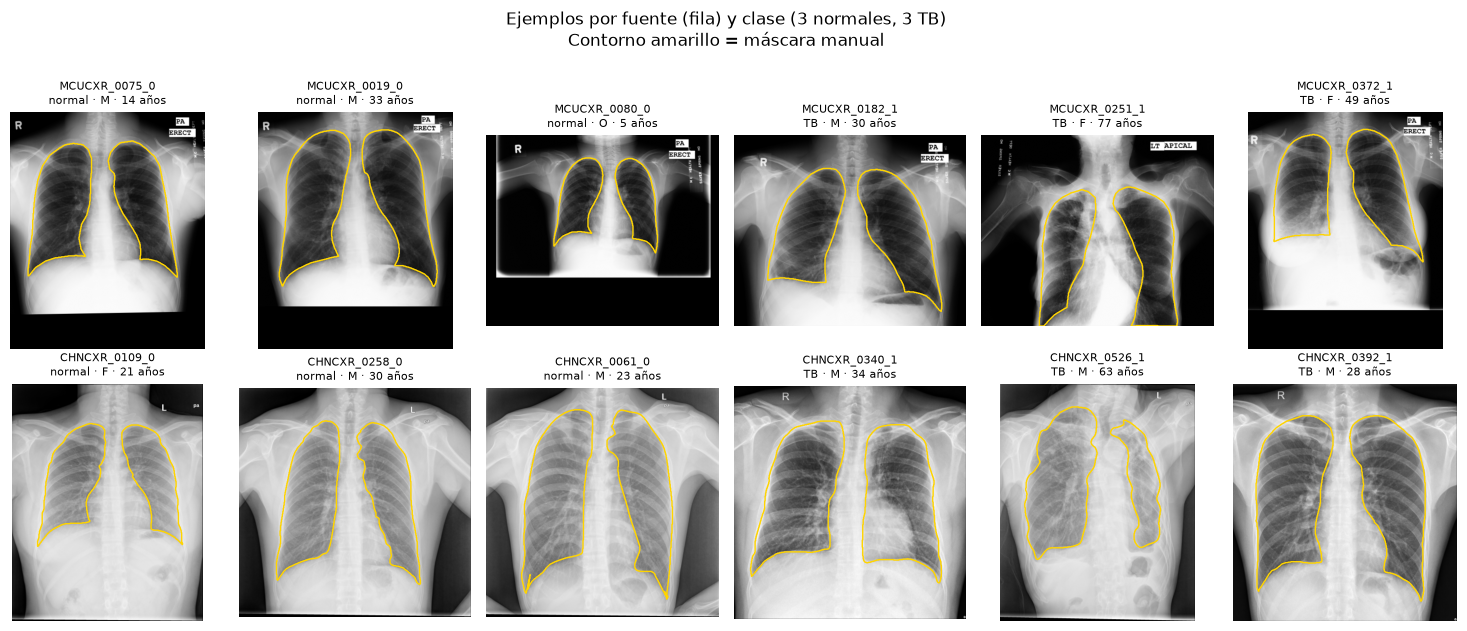

In [18]:
def load_pair(image_id: str, size: int = 512):
    """Carga una radiografía y su máscara, las escala a `size` px en el lado largo
    conservando la relación de aspecto."""
    img_path = IMG_DIR / f"{image_id}.png"
    msk_path = mask_path(image_id)

    img_arr  = np.frombuffer(img_path.read_bytes(), dtype=np.uint8)
    msk_arr  = np.frombuffer(msk_path.read_bytes(), dtype=np.uint8)
    img      = cv2.imdecode(img_arr, cv2.IMREAD_GRAYSCALE)
    mask_raw = cv2.imdecode(msk_arr, cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(f"No se pudo leer la imagen: {img_path}")
    if mask_raw is None:
        raise FileNotFoundError(f"No se pudo leer la máscara: {msk_path}")

    scale  = size / max(img.shape)
    dsize  = (round(img.shape[1] * scale), round(img.shape[0] * scale))
    img_r  = cv2.resize(img,      dsize, interpolation=cv2.INTER_AREA)
    mask_r = cv2.resize(mask_raw, dsize, interpolation=cv2.INTER_AREA) > 127
    return img_r, mask_r


def show_with_mask(ax, image_id, title=None):
    """Dibuja una radiografía con el contorno de su máscara en amarillo."""
    img, mask = load_pair(image_id)
    ax.imshow(img, cmap="gray")
    ax.contour(mask, levels=[0.5], colors=["#ffd400"], linewidths=1)
    ax.set_title(title or image_id, fontsize=8)
    ax.axis("off")


# Selecciono ejemplos representativos: 3 normales y 3 TB por fuente.
# El índice ya está filtrado: solo contiene imágenes con máscara disponible.
# Incluyo MCUCXR_0182_1 porque es un caso de TB pleural interesante.
examples = []
for source in SOURCE_ORDER:
    for tb in CLASS_NAMES:
        ids = index.query("source == @source and tb == @tb")["image_id"].to_numpy()
        if len(ids) < 3:
            raise ValueError(f"Menos de 3 imágenes disponibles: source={source}, tb={tb}")
        chosen = list(rng.choice(ids, 3, replace=False))
        if source == "montgomery" and tb == 1 and "MCUCXR_0182_1" not in chosen:
            chosen[0] = "MCUCXR_0182_1"
        examples.append((source, tb, chosen))

fig, axes = plt.subplots(2, 6, figsize=(15, 6.2))
for r, source in enumerate(SOURCE_ORDER):
    row_ids = [(tb, i) for s, tb, chosen in examples if s == source for i in chosen]
    for c, (tb, image_id) in enumerate(row_ids):
        meta_row = index.set_index("image_id").loc[image_id]
        show_with_mask(
            axes[r, c], image_id,
            f"{image_id}\n{CLASS_NAMES[tb]} · {meta_row['sex']} · {meta_row['age']:.0f} años"
        )

plt.suptitle("Ejemplos por fuente (fila) y clase (3 normales, 3 TB)\nContorno amarillo = máscara manual", y=1.01)
plt.tight_layout()
plt.show()

### 4.2 Formato de las imágenes

In [ ]:
# Leo las 704 imágenes y sus máscaras una sola vez para registrar el formato
# de cada una y calcular métricas que uso en las secciones siguientes:
#   - left_share: fracción del pulmón que cae en la mitad izquierda de la imagen
#     (lo uso en la sección 5 para detectar máscaras atípicas)
#   - md5: hash del canal de grises (lo uso en la sección 6 para detectar duplicados)
#
# Paralelizo con ThreadPoolExecutor porque cv2.imread libera el GIL al leer PNG,
# así que unos pocos hilos aceleran bastante sin disparar la memoria.

def analyze(image_id: str) -> dict:
    raw      = cv2.imread(str(IMG_DIR / f"{image_id}.png"), cv2.IMREAD_UNCHANGED)
    mask_raw = cv2.imread(str(mask_path(image_id)),         cv2.IMREAD_GRAYSCALE)

    channels      = 1 if raw.ndim == 2 else raw.shape[2]
    same_channels = channels == 1 or all(
        np.array_equal(raw[..., 0], raw[..., c]) for c in range(1, channels)
    )
    gray = raw if raw.ndim == 2 else cv2.cvtColor(raw, cv2.COLOR_BGR2GRAY)
    lung = mask_raw > 127
    h, w = gray.shape

    # Fracción del pulmón en la mitad izquierda de la imagen.
    # En una máscara bilateral normal esto ronda el 54 %
    # (la mitad derecha tiene algo menos de pulmón porque ahí está el corazón).
    left_share = lung[:, : w // 2].sum() / lung.sum()

    return {
        "image_id":       image_id,
        "height":         h,
        "width":          w,
        "channels":       channels,
        "same_channels":  same_channels,
        "dtype":          str(raw.dtype),
        "lung_area_frac": lung.mean(),
        "left_share":     left_share,
        "md5":            hashlib.md5(gray.tobytes()).hexdigest(),
    }


with ThreadPoolExecutor(max_workers=4) as pool:
    results = list(
        tqdm(pool.map(analyze, index["image_id"]), total=len(index), desc="Analizando imágenes")
    )

img_stats = pd.DataFrame(results)
index     = index.merge(img_stats, on="image_id")
index["orientation"] = np.where(index["height"] >= index["width"], "vertical", "horizontal")

# Resumen de formato por fuente
fmt = index.groupby("source").agg(
    imagenes          = ("image_id",      "size"),
    canales           = ("channels",      lambda s: sorted(s.unique())),
    canales_idénticos = ("same_channels", "all"),
    tipo              = ("dtype",         lambda s: sorted(s.unique())),
    alto_px           = ("height",        lambda s: f"{s.min()}-{s.max()}"),
    ancho_px          = ("width",         lambda s: f"{s.min()}-{s.max()}"),
)
display(fmt.T)

Analizando imágenes:   0%|          | 0/704 [00:00<?, ?it/s]

- **Canales:** Montgomery viene en 1 canal; Shenzhen en 3 canales idénticos.
  En ambos casos puedo leer en escala de grises sin perder información.
- **Profundidad:** ambas fuentes son `uint8`. El ReadMe de Montgomery menciona 12 bits
  originales, así que esta versión ya fue reducida a 8.
- **Tamaño:** Montgomery mide siempre 4 020 × 4 892 px (vertical u horizontal).
  Shenzhen varía entre ~1 000 y 3 000 px de lado y su ReadMe no informa el espaciado.
  Antes de extraer características tendré que llevar todo a una resolución común.

## 5 · Detección de máscaras atípicas

In [ ]:
# Uso el campo left_share calculado en 4.2 para buscar máscaras raras.
#
# En una máscara bilateral normal el pulmón se reparte casi por mitades
# (un poco más a la izquierda porque el corazón ocupa parte de la derecha).
# Si a un pulmón le falta un trozo grande (por derrame, atelectasia, etc.),
# el porcentaje se aleja mucho de esa mediana: hacia 90 % si falta pulmón
# a la derecha, o hacia 30 % si falta a la izquierda.
#
# No fijo ningún umbral numérico: muestro las 6 máscaras más alejadas de la
# mediana y las reviso visualmente.

N_SHOW = 6
q1, med, q3 = index["left_share"].quantile([0.25, 0.5, 0.75])
print(f"Pulmón en la mitad izquierda — mediana: {100*med:.0f} % (RIC: {100*q1:.0f}–{100*q3:.0f} %)")

extremes = index.loc[(index["left_share"] - med).abs().nlargest(N_SHOW).index]
display(
    extremes[["image_id", "tb", "left_share", "finding"]]
    .assign(left_share=lambda d: (100 * d["left_share"]).round(1))
    .rename(columns={"left_share": "mitad izq. %"})
)

In [ ]:
fig, axes = plt.subplots(1, N_SHOW, figsize=(2.5 * N_SHOW, 3.3))
for ax, row in zip(axes, extremes.itertuples()):
    show_with_mask(
        ax, row.image_id,
        f"{row.image_id} · {CLASS_NAMES[row.tb]}\nmitad izq. = {100*row.left_share:.0f} %"
    )
plt.tight_layout()
plt.show()

Las 6 máscaras más extremas son casos TB de Shenzhen en los que un pulmón
quedó muy recortado. En `CHNCXR_0603_1` la mitad izquierda concentra el 91 % del pulmón.

Tres de esas lecturas mencionan derrame, atelectasia o líquido encapsulado;
en las otras tres solo dice PTB. La convención de anotación importa:
- **Montgomery** (NLM): ante patología severa se dibuja el borde *inferido*.
- **Shenzhen** (Kaggle): se delimita solo el pulmón aireado visible.

Esta diferencia de convención afecta el área y las características extraídas
en los casos más graves. La reportaré en el análisis de resultados.

## 6 · Duplicados exactos

In [ ]:
# El MD5 del canal de grises detecta copias idénticas incluso si el PNG está
# codificado de forma diferente (distintos niveles de compresión, metadatos, etc.)

exact = index[index.duplicated("md5", keep=False)]
print(f"Grupos de duplicados exactos: {exact['md5'].nunique()} ({len(exact)} imágenes)")
print(f"Total: {len(index)} imágenes de {index['patient_id'].nunique()} pacientes")

No hay duplicados exactos en este dataset. La única repetición conocida son
los 2 pacientes de Montgomery con varias radiografías, registrados en `patient_id`.
Al definir la partición de entrenamiento (notebook 02), agrupa sus imágenes
en la misma partición para evitar fuga de información.

## 7 · Guardado del índice

In [ ]:
# Guardo un índice con una fila por imagen y todos los metadatos calculados.
# Este archivo es el punto de entrada de los notebooks siguientes:
#   - 02_segmentacion: lee el índice para construir la partición de entrenamiento
#   - 03_radiomics (futuro): lo usará para cruzar características con diagnóstico

INDEX_COLS = [
    "image_id", "patient_id", "source", "tb",
    "sex", "age", "finding",
    "height", "width", "orientation", "channels",
    "lung_area_frac", "left_share", "md5",
]
out = index[INDEX_COLS].copy()
out["lung_area_frac"] = out["lung_area_frac"].round(4)
out["left_share"]     = out["left_share"].round(4)

MS_INDEX_CSV.parent.mkdir(parents=True, exist_ok=True)
out.to_csv(MS_INDEX_CSV, index=False)
print(f"Guardado: {MS_INDEX_CSV.relative_to(MS_INDEX_CSV.parents[2])}")
print(f"Forma: {out.shape}")
display(out.head())

## 8 · Conclusiones e implicaciones para el proyecto

### Datos utilizables
- 704 radiografías con máscara pulmonar manual y lectura clínica: 345 TB y 359 normales.
- No hay duplicados exactos. La única repetición son 2 pacientes de Montgomery
  con varias visitas (5 imágenes en total), controlados con `patient_id`.
- El índice queda en `data/metadata/montgomery_shenzhen_index.csv`.

### Preprocesado necesario antes de segmentar y extraer características
- Leer en escala de grises de 1 canal: no se pierde información en ninguna fuente.
- Llevar todas las imágenes a una resolución común (512 × 512 en el módulo `prepare`).
  Los tamaños y espaciados difieren entre fuentes y Shenzhen no informa el espaciado.

### Sesgos y confusores a tener en cuenta
- **Fuente:** las dos fuentes difieren en formato, tamaño y adquisición. Las métricas
  de los clasificadores se reportarán globalmente y también desglosadas por fuente.
- **Demografía en Montgomery:** los casos TB son mayores y más a menudo hombres.
  Afectan por igual a todos los métodos de segmentación, así que no sesgan la
  comparación entre ellos.
- **Etiqueta TB heterogénea:** la clase TB incluye casos activos, curados y en
  tratamiento, según las lecturas clínicas (columna `finding` del índice).
- **Convención de anotación de máscaras:** Montgomery dibuja el borde inferido
  ante patología severa; Shenzhen delimita solo el pulmón aireado visible.
  Esto puede afectar la comparación entre métodos en los casos más graves.